after completing training for ~3 days, the model stopped improving on results. in this notebook we evaluate the training process and what the model has learnt.

In [8]:
import os
import yaml
import torch
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from torch.utils.data import DataLoader
from transformers import AutoTokenizer
from askwiki.inference.chat import chat
from askwiki.data.classes.token import TokenSequence
from askwiki.training.config import Config
from askwiki.training.utils import generate_state, validate

load_dotenv()

CHECKPOINT_PATH=os.environ['CHECKPOINTPATH']
CONFIG_PATH=os.environ['CONFIGPATH']
DATA_PATH=os.environ['DATAPATH']

# load most recent checkpoint
state = torch.load(f'{CHECKPOINT_PATH}/base_latest.pt')

first, how did the loss history and the gradients look?

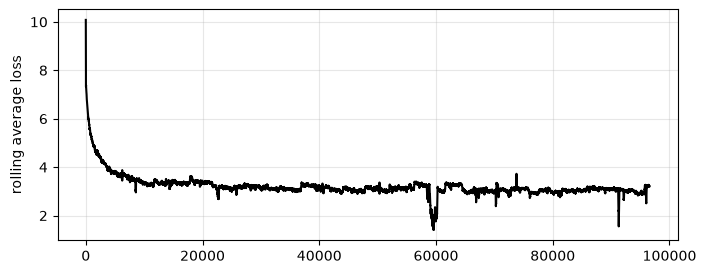

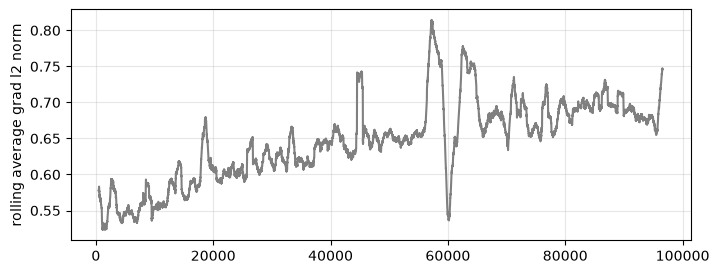

In [2]:
train_hist_df = pd.DataFrame(state['loss_hist'])
train_hist_df['grad_norm_roll'] = train_hist_df['grad_norm'].rolling(window=1000, min_periods=500).mean(numeric_only=True)

# loss history
plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['loss'], color='black')
plt.ylabel('rolling average loss')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['grad_norm_roll'], color='grey')
plt.ylabel('rolling average grad l2 norm')
plt.grid(alpha=0.3)
plt.show()

gradients became larger over time, but were still fairly constrained. clearly there were pockets of large and small gradients, and there is a particularly interesting part around step $60,000$ where the loss plummets to sub 2 for a moment. it is likely there is a set of either bad data, or repetitive data. during the period, the gradient norm skyrockets as the model believes it has founds a new direction of loss minimisation. either way, the model looks to be "properly fit" for it's parameter size.

what is the test loss?

In [3]:
with open(f'{CONFIG_PATH}/base.yaml', 'r') as file:
    config = Config(**yaml.safe_load(file)['config'])

# create state object and load in trained net
state_obj = generate_state(config, {'AdamW': torch.optim.AdamW})
state_obj.load_state_dict(state)

In [ ]:
test_set = TokenSequence(f'{DATA_PATH}/test.bin', np.uint16, 512)
test_loss = validate(state_obj, DataLoader(test_set, 32))

print(f'test loss: {test_loss:.2f}')
print(f'train loss (last 1,000 steps): {np.mean(train_hist_df.iloc[-1000:]['loss']):.2f}')

test loss: 3.07
train loss (last 1,000 steps): 3.10


comparing our test loss with the training loss shows us that we have not overfit the model, since both losses are very comparable. it is difficult to ascertain what *sort* of text the language model produces. thus, consider a `chat` function at temperature $0.8$ for some example prompts. since wikipedia articles are often quite long, it is likely that our pre-trained model will be incentivised to create longer sequences of text.

In [4]:
tokeniser = AutoTokenizer.from_pretrained("notoverfit/askwiki", subfolder="tokenizer")
device = torch.device('cuda')

In [18]:
prompts = [
    "The Amazon River in South America is the largest river in the world by discharge "
    "volume of water. It flows through Peru, Colombia and Brazil before reaching the "
    "Atlantic Ocean. The river",

    "The French Revolution was a period of political and social change in France that "
    "began in 1789. It led to the end of the monarchy and the rise of a republic. "
    "One of the main causes of the revolution was",

    "The human heart is a muscular organ that pumps blood through the body. It is "
    "located in the chest, between the lungs. The heart is divided into four chambers,",

    "Albert Einstein was a German-born theoretical physicist who developed the theory "
    "of relativity. He received the Nobel Prize in Physics in 1921. Einstein was born in",

    "Tokyo is the capital and largest city of Japan. It is located on the eastern coast "
    "of the main island of Honshu. The city's economy",

    "Cricket is a bat-and-ball game played between two teams of eleven players. "
    "It is especially popular in England, Australia and India. A match begins when",

    "The printing press is a machine that applies pressure to an inked surface to "
    "transfer text or images onto paper. It was developed in Europe in the 15th century. "
    "Before the printing press,",

    "The Moon is the only natural satellite of the Earth. It is about one quarter the "
    "width of the Earth and orbits at an average distance of 384,400 kilometres. "
    "The surface of the Moon",

    "The Second World War was a global conflict that lasted from 1939 to 1945. "
    "It involved most of the world's nations, including all of the great powers. "
    "The war began when",

    "Millbrook is a small village in the south of the county, located near the "
    "Millbrook River. The village grew around a wool mill built in the early 19th century. "
    "Today, most residents",
]

for prompt in prompts:
    print(textwrap.fill(prompt + chat(state_obj.net, tokeniser, device, prompt='The United States of America', temperature=0.7, max_new_tokens=256), width=80))
    print()

The Amazon River in South America is the largest river in the world by discharge
volume of water. It flows through Peru, Colombia and Brazil before reaching the
Atlantic Ocean. The river became the first country to share its history with the
European Union. The United States of America became the first country to join
the European Union in July 2003, and the United States became the first country
to join the Council of Europe in July 2004.  Unlike the United States, which had
no recognition to the world's right to join the European Union, the United
States has never joined the European Union, or did so when the European
Provinces of the European Union and the United States joined the European Union
but which had been established since 1967.  Following the addition of the United
States in February 2013, the European Council of Trade Unions (ECTO) has since
recently been set up to meet the growing number of countries whose membership is
funded by the European Union. The ECTO was establis

so the model has learnt to form semi-coherent sentences of english, but struggles with retention of key historical facts, which should be expected from a model with only ~100M parameters. the key here is that the model writes in a "Wikipedia" like, fact-of-the-matter, informative way. depending on the temperature, the model seems to at times, latch onto previous statements and repeat them over and over again. this is occasionally a problem even with the frontier models, and something that you have may experienced whilst using Claude/ChatGPT.

given our model has successfully learnt to form english sentences and write in a "wikipedia" like fashion, our next step is to fine-tune the model, with guidance from a larger LLM, to respond to `User: <question> Assistant: <response>` type chatbot conversations. we do this with supervised fine tuning. the idea is that the model has encoded the knowledge of wikipedia type information into it's parameters, and that if we give a larger model the task of producing Q&A-style training samples, the model's parameters retain the information it learnt but is steered towards responding in a more succinct, Q&A way.